# Analiza interactivă și vizualizarea datelor din comerțul online

**Autor:** Denis Zabolotnîi

## Introducere
Scopul acestei analize este de a studia evaluările produselor dintr-un magazin online și de a prezenta rezultatele într-un mod clar pentru o echipă de marketing. Vom analiza valorile extreme ale evaluărilor, evoluția notei medii în timp și diferențele dintre categoriile de produse.

## 1. Pregătirea datelor
Încărcăm setul de date și verificăm structura acestuia.

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from tkinter import Tk, filedialog

root = Tk()
root.withdraw()

file_path = filedialog.askopenfilename(
    title="Selecteaza fisierul CSV",
    filetypes=[("CSV files", "*.csv")]
)

root.destroy()

print("Fisier selectat:", file_path)

df = pd.read_csv(file_path)

if 'date_added' not in df.columns:
    print("Coloana 'date_added' nu a fost gasita. Coloane disponibile:", df.columns.tolist())
else:
    df["date_added"] = pd.to_datetime(df["date_added"], errors='coerce')
    df["year"] = df["date_added"].dt.year
print("Dimensiunea setului de date:", df.shape)
display(df.head())

Fisier selectat: C:/Users/zds19/OneDrive/F0A5~1/INTRO_~1/REZOLV~1/84394~1.INT/DENIS_~2/ONLINE~1.CSV
Dimensiunea setului de date: (3078, 12)


,product_name,category,price,quantity_in_stock,quantity_sold,brand,rating,num_of_ratings,date_added,color,revenue,year
0,"iPad mini (2021) (64GB, Blue)",Tablets,499.00,266.0,185.0,Apple,8.75,151.0,2022-02-02,blue,92315.00,2022
1,K55 RGB (Red),Keyboards,49.99,0.0,561.0,Corsair,8.50,455.0,2022-08-14,red,28044.39,2022
2,Fenix 7 (Purple),Watches,699.99,0.0,374.0,Garmin,9.20,305.0,2022-04-20,purple,261796.26,2022
3,"Mate 40 (256GB, Orange)",Smartphones,899.00,182.0,615.0,Huawei,8.50,500.0,2024-10-23,orange,552885.00,2024
4,Rival 600 (Red),Mice,79.99,35.0,698.0,SteelSeries,9.25,556.0,2020-09-29,red,55833.02,2020


## 2. Nota maximă și nota minimă

In [5]:
max_rating = df["rating"].max()
min_rating = df["rating"].min()

print(f"Nota maximă primită de un produs: {max_rating}")
print(f"Nota minimă primită de un produs: {min_rating}")


Nota maximă primită de un produs: 9.75
Nota minimă primită de un produs: 5.5


## 3. Evoluția notei medii de-a lungul anilor

Extragem anul din `date_added`, grupăm produsele după an și calculăm nota medie. Conform cerinței, rezultatul este reprezentat printr-o diagramă liniară.

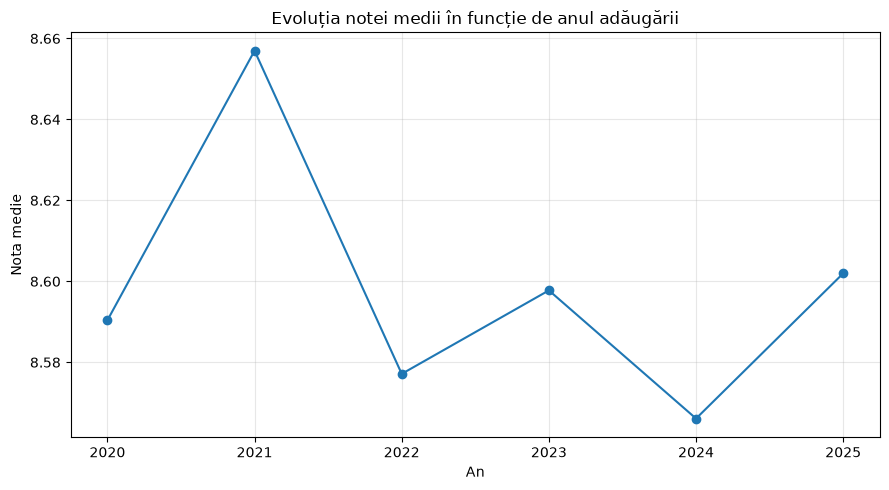

In [6]:
rating_by_year = df.groupby("year")["rating"].mean()

plt.figure(figsize=(9, 5))
plt.plot(rating_by_year.index, rating_by_year.values, marker="o")
plt.title("Evoluția notei medii în funcție de anul adăugării")
plt.xlabel("An")
plt.ylabel("Nota medie")
plt.xticks(rating_by_year.index)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 4. Nota medie pe categorii de produse

Calculăm media evaluărilor pentru fiecare categorie și folosim o diagramă cu bare pentru a compara categoriile.

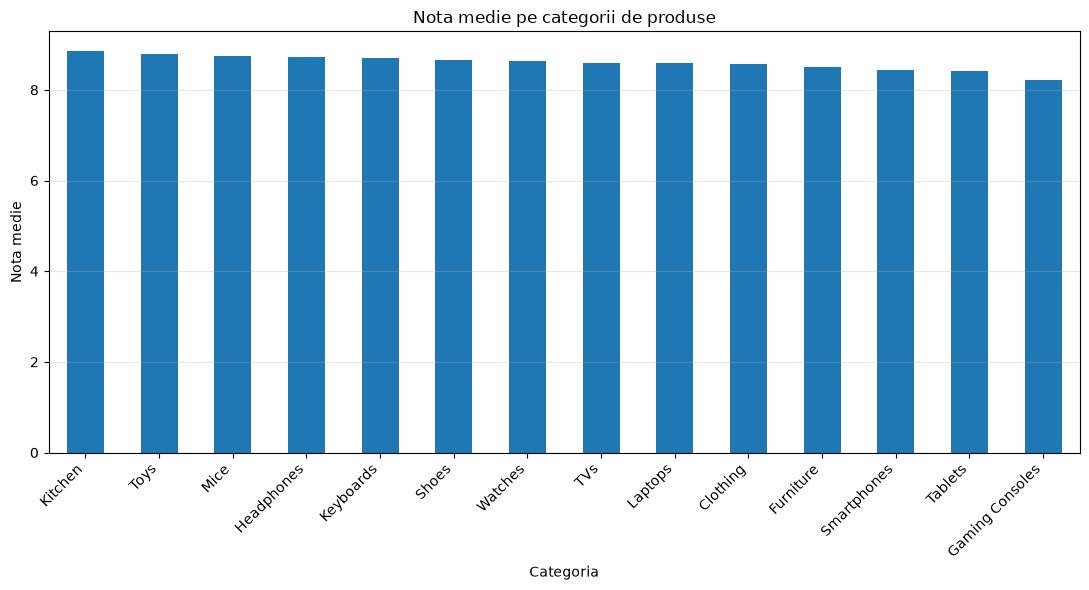

In [7]:
rating_by_category = df.groupby("category")["rating"].mean().sort_values(ascending=False)

plt.figure(figsize=(11, 6))
rating_by_category.plot(kind="bar")
plt.title("Nota medie pe categorii de produse")
plt.xlabel("Categoria")
plt.ylabel("Nota medie")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


## 5. Concluzie

Evaluările produselor sunt în general ridicate. Nota maximă din set este **9,75**, iar nota minimă este **5,5**. Evoluția anuală a notei medii este relativ stabilă, cu mici variații între ani. La nivel de categorii, **Kitchen** are cea mai mare notă medie, iar **Gaming Consoles** cea mai mică.

Din perspectiva echipei de marketing, diferențele dintre categorii pot indica zone în care experiența utilizatorilor este mai bună sau unde ar putea fi necesare investigații suplimentare.

## 6. Reflecție

Lucrul cu graficele arată că alegerea formei de vizualizare depinde de întrebarea analizată. Diagrama liniară este potrivită pentru observarea evoluției în timp, în timp ce diagrama cu bare permite compararea rapidă a categoriilor. Data viitoare aș putea extinde analiza prin compararea evaluărilor cu numărul de recenzii sau cu veniturile produselor.